# F Distribution

This notebook accompanies [F Distribution](../../notes/sampling_and_sampling_distributions/f_distribution.md). We build the F distribution as a ratio of scaled chi-squares, check formulas against `scipy.stats`, and apply it to a variance-ratio test and an ANOVA table.

## Ratio of scaled chi-squares

If $U\sim\chi^2(d_1)$ and $V\sim\chi^2(d_2)$ are independent then $F=(U/d_1)/(V/d_2)\sim F(d_1,d_2)$.

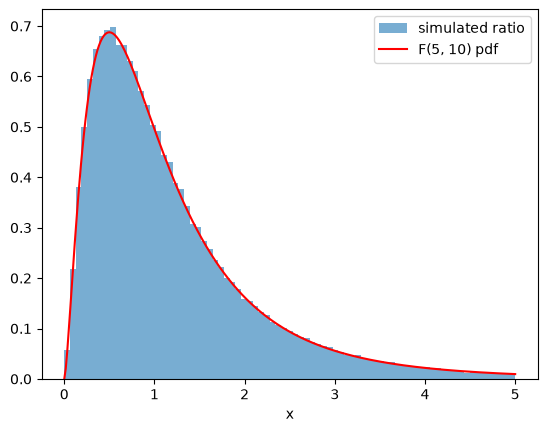

sim mean: 1.252  theory: 1.25


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

d1, d2 = 5, 10
u = rng.chisquare(d1, 200_000)
v = rng.chisquare(d2, 200_000)
fvals = (u / d1) / (v / d2)

xs = np.linspace(0, 5, 300)
plt.hist(fvals, bins=np.linspace(0, 5, 80), density=True, alpha=0.6, label="simulated ratio")
plt.plot(xs, stats.f.pdf(xs, d1, d2), "r", label="F(5, 10) pdf")
plt.legend(); plt.xlabel("x"); plt.show()
print("sim mean:", round(fvals.mean(), 3), " theory:", d2 / (d2 - 2))

## Formulas versus `scipy.stats`

The CDF is the regularized incomplete beta function evaluated at $d_1x/(d_1x+d_2)$, and the moments are $E=d_2/(d_2-2)$, $\operatorname{Var}=\frac{2d_2^2(d_1+d_2-2)}{d_1(d_2-2)^2(d_2-4)}$.

In [2]:
from scipy.special import betainc, beta

x = np.linspace(0.05, 5, 100)
pdf_formula = np.sqrt((d1 * x) ** d1 * d2 ** d2 / (d1 * x + d2) ** (d1 + d2)) / (x * beta(d1 / 2, d2 / 2))
cdf_formula = betainc(d1 / 2, d2 / 2, d1 * x / (d1 * x + d2))
print("pdf agrees:", np.allclose(pdf_formula, stats.f.pdf(x, d1, d2)))
print("cdf agrees:", np.allclose(cdf_formula, stats.f.cdf(x, d1, d2)))
var_formula = 2 * d2**2 * (d1 + d2 - 2) / (d1 * (d2 - 2) ** 2 * (d2 - 4))
print("variance:", var_formula, stats.f.var(d1, d2))

pdf agrees: True
cdf agrees: True
variance: 1.3541666666666667 1.3541666666666667


## Variance-ratio test

Wheat varieties: $n_1=15$, $s_1^2=20$; $n_2=12$, $s_2^2=30$. Under $H_0:\sigma_1^2=\sigma_2^2$, $F=s_1^2/s_2^2\sim F(14,11)$.

In [3]:
F_obs = 20 / 30
df1, df2 = 14, 11
p_lower = stats.f.cdf(F_obs, df1, df2)
print("F =", round(F_obs, 4), " lower tail =", round(p_lower, 4), " two-sided p =", round(2 * p_lower, 4))
crit = stats.f.ppf([0.025, 0.975], df1, df2)
print("95% acceptance region:", np.round(crit, 4))
print("95% CI for sigma1^2/sigma2^2:", np.round(F_obs / crit[::-1], 4))

F = 0.6667  lower tail = 0.2346  two-sided p = 0.4692
95% acceptance region: [0.3231 3.3588]
95% CI for sigma1^2/sigma2^2: [0.1985 2.0631]


## Reciprocal property and the link to $t$

If $F\sim F(d_1,d_2)$ then $1/F\sim F(d_2,d_1)$, and $t_\nu^2\sim F(1,\nu)$.

In [4]:
print("F_0.95(4,9) =", round(stats.f.ppf(0.95, 4, 9), 4), " 1/F_0.05(9,4) =", round(1 / stats.f.ppf(0.05, 9, 4), 4))
t_val, nu = 2.5, 20
print("two-sided t p-value:", round(2 * stats.t.sf(t_val, nu), 5), " F(1,20) p-value:", round(stats.f.sf(t_val ** 2, 1, nu), 5))

F_0.95(4,9) = 3.6331  1/F_0.05(9,4) = 3.6331
two-sided t p-value: 0.02123  F(1,20) p-value: 0.02123


## ANOVA with the F distribution

Three groups of 10 with $SSB=48$ and $SSW=270$. We also run a full simulated one-way ANOVA under $H_0$ and check that p-values are uniform.

In [5]:
msb, msw = 48 / 2, 270 / 27
F_anova = msb / msw
print("F =", F_anova, " p =", round(stats.f.sf(F_anova, 2, 27), 4), " 5% critical:", round(stats.f.ppf(0.95, 2, 27), 3))

pvals = np.array([stats.f_oneway(*rng.normal(0, 1, size=(3, 10))).pvalue for _ in range(5000)])
print("Share of p-values < 0.05 under H0:", round((pvals < 0.05).mean(), 4))

F = 2.4  p = 0.1098  5% critical: 3.354


Share of p-values < 0.05 under H0: 0.0486
